# Tuần 1 — Regression: Bài tập ở lớp và bài tập về nhà


## I. Chuẩn bị môi trường

**CAI THU VIEN CAN THIET**

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score)

SEED = 42
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'font.size': 11})
pd.set_option('display.max_columns', 16)

In [ ]:
# Cell 3: Hàm dùng chung để tính sai số hồi quy và kiểm tra chất lượng dữ liệu.
def regression_scores(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

def inspect_data(df):
    print('Kích thước:', df.shape)
    print('Số giá trị thiếu:', int(df.isna().sum().sum()))
    print('Số dòng trùng:', int(df.duplicated().sum()))
    display(df.head())
    display(df.describe().round(2))

## II. Bài tập ở lớp
### Bài 1. Dự đoán giá nhà
**Yêu cầu 1:** Dùng diện tích (m²) để dự đoán giá (triệu VND).
Sinh dữ liệu theo công thức giả định `giá = 500 + 35 × diện tích + nhiễu`.
Đây là dữ liệu mô phỏng phục vụ học tập, không phải giá thị trường.

In [ ]:
# Cell 4: Tạo 120 căn nhà với nhiễu Gaussian có độ lệch chuẩn 300 triệu VND.
rng = np.random.default_rng(SEED)
area = rng.uniform(30, 200, 120)
house = pd.DataFrame({'DienTich': area,
                     'GiaBan': 500 + 35 * area + rng.normal(0, 300, len(area))})
inspect_data(house)

Kích thước: (120, 2)
Số giá trị thiếu: 0
Số dòng trùng: 0


,DienTich,GiaBan
0,161.572528,6635.572156
1,104.609335,4089.520028
2,175.961646,6351.608376
3,148.552565,5753.122463
4,46.010149,2176.354225


,DienTich,GiaBan
count,120.00,120.00
mean,114.78,4514.64
std,46.54,1655.68
min,31.25,1581.58
25%,76.01,2965.49
50%,109.96,4457.40
75%,153.75,5828.30
max,195.86,7762.71


In [ ]:
# Cell 5: Chia 80% train, 20% test và chỉ huấn luyện trên train.
X_h = house[['DienTich']]
y_h = house['GiaBan']
X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    X_h, y_h, test_size=0.2, random_state=SEED)
house_model = LinearRegression().fit(X_h_train, y_h_train)
pred_h = house_model.predict(X_h_test)
print(f'Giá dự đoán = {house_model.intercept_:.2f} + {house_model.coef_[0]:.2f} × Diện tích')
display(pd.DataFrame([regression_scores(y_h_test, pred_h)]))

Giá dự đoán = 562.69 + 34.44 × Diện tích

,MSE,RMSE,R2
0,93202.876798,305.291462,0.969484


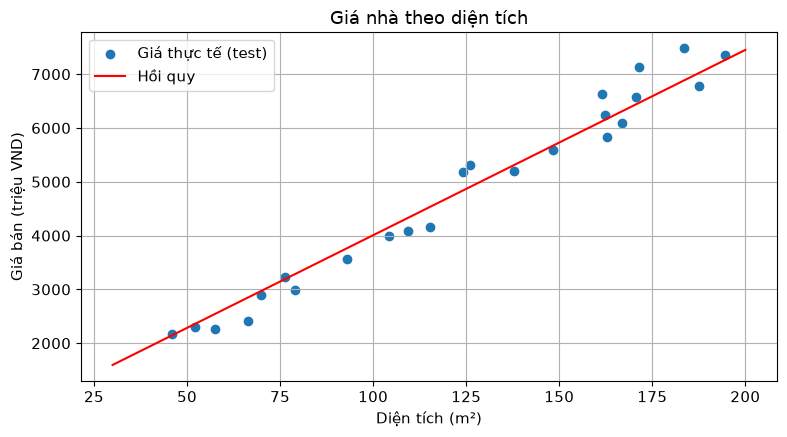

,DienTich,GiaDuDoan
0,50,2284.90
1,80,3318.23
2,120,4696.01


In [ ]:
# Cell 6: Vẽ đường hồi quy trên lưới đã sắp tăng để đường không bị nối lộn xộn.
grid_h = pd.DataFrame({'DienTich': np.linspace(30, 200, 200)})
plt.scatter(X_h_test['DienTich'], y_h_test, label='Giá thực tế (test)')
plt.plot(grid_h['DienTich'], house_model.predict(grid_h), color='red', label='Hồi quy')
plt.xlabel('Diện tích (m²)'); plt.ylabel('Giá bán (triệu VND)')
plt.title('Giá nhà theo diện tích'); plt.legend(); plt.tight_layout(); plt.show()
new_houses = pd.DataFrame({'DienTich': [50, 80, 120]})
display(new_houses.assign(GiaDuDoan=house_model.predict(new_houses)).round(2))

**Yêu cầu 2:** Tăng số mẫu và độ nhiễu. Thử 100, 500, 2000 mẫu và σ = 100, 500, 1000.
Lặp 10 seed và đánh giá trên một tập test độc lập cố định về diện tích và nhiễu chuẩn.
`RMSE_tin_hieu` đo mức khôi phục đường giá không nhiễu; `RMSE` đo sai số trên giá có nhiễu.

In [ ]:
# Cell 7: Thí nghiệm có kiểm soát để tách ảnh hưởng số mẫu và nhiễu.
rng_test = np.random.default_rng(2026)
area_eval = rng_test.uniform(30, 200, (1000, 1))
signal_eval = 500 + 35 * area_eval.ravel()
noise_eval = rng_test.normal(size=1000)
rows = []
for seed in range(10):
    generator = np.random.default_rng(seed)
    all_area = generator.uniform(30, 200, (2000, 1))
    all_noise = generator.normal(size=2000)
    for n in [100, 500, 2000]:
        for sigma in [100, 500, 1000]:
            target = 500 + 35 * all_area[:n, 0] + sigma * all_noise[:n]
            fitted = LinearRegression().fit(all_area[:n], target)
            predictions = fitted.predict(area_eval)
            rows.append({'n': n, 'sigma': sigma,
                **regression_scores(signal_eval + sigma * noise_eval, predictions),
                'RMSE_tin_hieu': np.sqrt(mean_squared_error(signal_eval, predictions))})
sample_experiment = pd.DataFrame(rows).groupby(['n', 'sigma']).mean().reset_index()
display(sample_experiment.round(3))

,n,sigma,MSE,RMSE,R2,RMSE_tin_hieu
0,100,100,10016.484,100.077,0.997,12.610
1,100,500,250412.098,500.387,0.921,63.048
2,100,1000,1001648.394,1000.774,0.747,126.097
3,500,100,9759.185,98.788,0.997,4.121
4,500,500,243979.618,493.941,0.923,20.606
5,500,1000,975918.472,987.882,0.753,41.211
6,2000,100,9773.135,98.859,0.997,2.684
7,2000,500,244328.368,494.295,0.923,13.420
8,2000,1000,977313.470,988.590,0.753,26.840


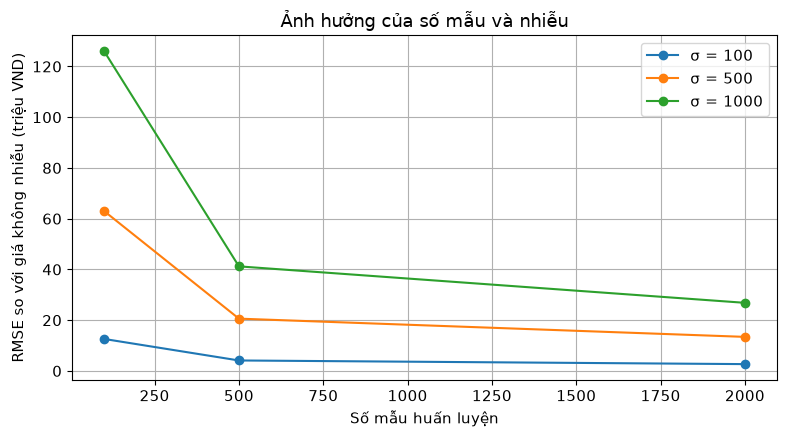

In [ ]:
# Cell 8: So sánh sai số khôi phục đường giá khi tăng số mẫu ở từng mức nhiễu.
for sigma, group in sample_experiment.groupby('sigma'):
    plt.plot(group['n'], group['RMSE_tin_hieu'], marker='o', label=f'σ = {sigma}')
plt.xlabel('Số mẫu huấn luyện'); plt.ylabel('RMSE so với giá không nhiễu (triệu VND)')
plt.title('Ảnh hưởng của số mẫu và nhiễu'); plt.legend(); plt.tight_layout(); plt.show()

**Nhận xét:** Nhiễu lớn làm dự đoán giá quan sát khó hơn. Tăng số mẫu thường giúp ước lượng
đường giá ổn định hơn nhưng không loại bỏ nhiễu ngẫu nhiên trong giá bán.
Xu hướng được đánh giá trung bình qua nhiều seed, không khẳng định mọi lần chạy đều đơn điệu.

**Yêu cầu 3:** Thêm số phòng ngủ, khoảng cách đến trung tâm và tuổi nhà.
So sánh mô hình một biến và đa biến trên **cùng dữ liệu, cùng train/test**.

In [ ]:
# Cell 9: Sinh dữ liệu đa biến; mọi thành phần của y đều có shape (600,).
# Tránh cộng mảng (n,) với (n, 1), vì broadcasting sẽ tạo nhầm y có shape (n, n).
rng = np.random.default_rng(SEED)
multi_house = pd.DataFrame({
    'DienTich': rng.uniform(30, 200, 600),
    'PhongNgu': rng.integers(1, 6, 600),
    'KhoangCach': rng.uniform(1, 30, 600),
    'TuoiNha': rng.uniform(0, 40, 600)})
multi_house['GiaBan'] = (1000 + 35 * multi_house['DienTich']
    + 250 * multi_house['PhongNgu'] - 40 * multi_house['KhoangCach']
    - 15 * multi_house['TuoiNha'] + rng.normal(0, 200, 600))
inspect_data(multi_house)

Kích thước: (600, 5)
Số giá trị thiếu: 0
Số dòng trùng: 0


,DienTich,PhongNgu,KhoangCach,TuoiNha,GiaBan
0,161.572528,5,14.584083,26.874168,6991.852901
1,104.609335,3,8.523755,38.423479,4610.645952
2,175.961646,5,2.310020,14.836493,7995.137461
3,148.552565,4,14.963249,17.003271,5983.718093
4,46.010149,4,28.820638,32.484918,1849.712047


,DienTich,PhongNgu,KhoangCach,TuoiNha,GiaBan
count,600.00,600.00,600.00,600.00,600.00
mean,114.32,2.99,15.63,20.13,4829.15
std,48.83,1.42,8.49,11.52,1830.17
min,30.92,1.00,1.02,0.02,1151.83
25%,70.24,2.00,8.14,10.00,3273.45
50%,114.96,3.00,15.22,19.25,4831.22
75%,157.55,4.00,23.22,30.40,6360.57
max,199.85,5.00,29.98,39.95,8944.22


In [ ]:
# Cell 10: Huấn luyện hai mô hình trên cùng cách chia và so sánh chỉ số test.
X_m = multi_house.drop(columns='GiaBan'); y_m = multi_house['GiaBan']
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(X_m, y_m, test_size=0.2, random_state=SEED)
simple_m = LinearRegression().fit(Xm_tr[['DienTich']], ym_tr)
multiple_m = LinearRegression().fit(Xm_tr, ym_tr)
display(pd.DataFrame([
    {'MoHinh': 'Chỉ diện tích', **regression_scores(ym_te, simple_m.predict(Xm_te[['DienTich']]))},
    {'MoHinh': 'Đủ 4 biến', **regression_scores(ym_te, multiple_m.predict(Xm_te))}]))
display(pd.DataFrame({'Bien': X_m.columns, 'HeSoThuc': [35, 250, -40, -15],
                      'HeSoHocDuoc': multiple_m.coef_}))
print('Hệ số chặn:', multiple_m.intercept_)

,MoHinh,MSE,RMSE,R2
0,Chỉ diện tích,315081.405242,561.321125,0.904247
1,Đủ 4 biến,39945.661340,199.864107,0.987861


,Bien,HeSoThuc,HeSoHocDuoc
0,DienTich,35,34.816927
1,PhongNgu,250,238.735037
2,KhoangCach,-40,-41.556902
3,TuoiNha,-15,-15.490315


Hệ số chặn: 1095.023989149442


**Nhận xét:** Mô hình đủ 4 biến có thể giải thích các thành phần giá bị bỏ sót trong mô hình
chỉ dùng diện tích. Hệ số học được nên gần hệ số sinh dữ liệu, nhưng không trùng hoàn toàn vì có nhiễu.
Thêm biến chỉ có ích khi biến chứa thông tin phù hợp; không phải cứ thêm biến là tốt hơn.

### Bài 2. Logistic Regression với BMI
Sinh xác suất `p = sigmoid(0.4 × (BMI − 27))`, sau đó lấy nhãn theo Bernoulli(p).
Cách này cho phép người có BMI giống nhau vẫn có nhãn khác nhau.
Quan hệ này **chỉ là giả định mô phỏng**, không dùng để chẩn đoán bệnh.

In [ ]:
# Cell 11: Sinh 600 mẫu BMI và nhãn bệnh dựa trên xác suất, không gán nhãn cứng.
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

rng = np.random.default_rng(SEED)
bmi_values = rng.uniform(16, 40, 600)
true_probability = sigmoid(0.4 * (bmi_values - 27))
bmi = pd.DataFrame({'BMI': bmi_values, 'MacBenh': rng.binomial(1, true_probability)})
inspect_data(bmi)
print('Phân bố nhãn:', bmi['MacBenh'].value_counts().sort_index().to_dict())

Kích thước: (600, 2)
Số giá trị thiếu: 0
Số dòng trùng: 0


,BMI,MacBenh
0,34.574945,1
1,26.533083,1
2,36.606350,1
3,32.736833,1
4,18.260256,0


,BMI,MacBenh
count,600.00,600.00
mean,27.90,0.54
std,6.89,0.50
min,16.13,0.00
25%,21.68,0.00
50%,27.99,1.00
75%,34.01,1.00
max,39.98,1.00


Phân bố nhãn: {0: 274, 1: 326}


In [ ]:
# Cell 12: Chia phân tầng để giữ tỷ lệ hai nhãn, chuẩn hóa chỉ bằng tập train.
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    bmi[['BMI']], bmi['MacBenh'], test_size=0.2, random_state=SEED, stratify=bmi['MacBenh'])
bmi_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
bmi_model.fit(Xb_tr, yb_tr)
prob_bmi = bmi_model.predict_proba(Xb_te)[:, 1]
pred_bmi = (prob_bmi >= 0.5).astype(int)
display(pd.DataFrame({'BMI': Xb_te['BMI'], 'NhanThuc': yb_te,
                      'XacSuatBenh': prob_bmi, 'NhanDuDoan': pred_bmi}).head(12))

,BMI,NhanThuc,XacSuatBenh,NhanDuDoan
595,22.672531,0,0.174072,0
98,18.832142,0,0.047483,0
356,34.334161,1,0.943790,1
104,34.690022,1,0.950471,1
223,38.934958,1,0.989522,1
490,32.848052,1,0.905759,1
257,18.526674,0,0.042557,0
469,28.200466,1,0.626722,1
44,35.974235,1,0.968826,1
523,30.420170,1,0.794370,1


Accuracy: 0.8333
Ma trận [[TN, FP], [FN, TP]]:
[[44 11]
 [ 9 56]]


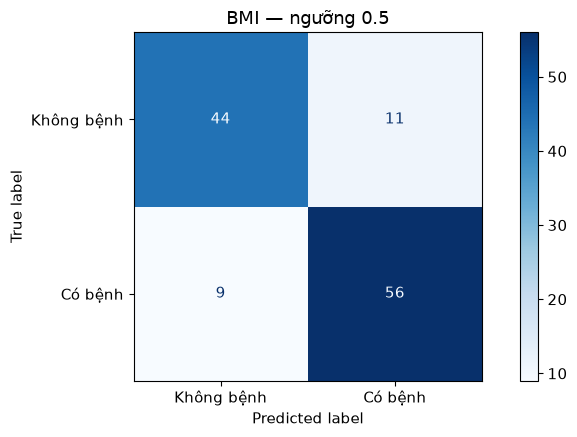

In [ ]:
# Cell 13: Đánh giá accuracy và ma trận nhầm lẫn trên dữ liệu chưa dùng huấn luyện.
print(f'Accuracy: {accuracy_score(yb_te, pred_bmi):.4f}')
cm_bmi = confusion_matrix(yb_te, pred_bmi, labels=[0, 1])
print('Ma trận [[TN, FP], [FN, TP]]:'); print(cm_bmi)
ConfusionMatrixDisplay(cm_bmi, display_labels=['Không bệnh', 'Có bệnh']).plot(cmap='Blues')
plt.title('BMI — ngưỡng 0.5'); plt.grid(False); plt.tight_layout(); plt.show()

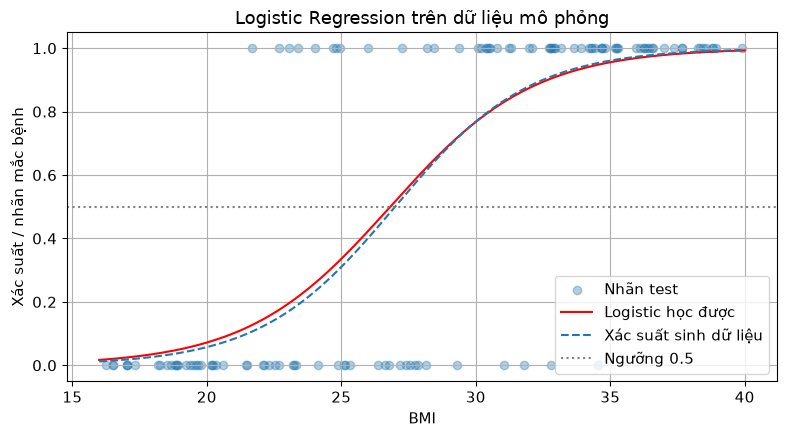

In [ ]:
# Cell 14: Vẽ dữ liệu test, đường logistic đã học và xác suất sinh dữ liệu.
bmi_grid = pd.DataFrame({'BMI': np.linspace(16, 40, 300)})
plt.scatter(Xb_te['BMI'], yb_te, alpha=0.35, label='Nhãn test')
plt.plot(bmi_grid['BMI'], bmi_model.predict_proba(bmi_grid)[:, 1], color='red', label='Logistic học được')
plt.plot(bmi_grid['BMI'], sigmoid(0.4 * (bmi_grid['BMI'] - 27)), '--', label='Xác suất sinh dữ liệu')
plt.axhline(0.5, color='gray', linestyle=':', label='Ngưỡng 0.5')
plt.xlabel('BMI'); plt.ylabel('Xác suất / nhãn mắc bệnh')
plt.title('Logistic Regression trên dữ liệu mô phỏng'); plt.legend(); plt.tight_layout(); plt.show()

**Nhận xét:** Đường sigmoid biểu diễn xác suất tăng theo BMI theo giả thiết đã đặt.
Không kỳ vọng accuracy 100% vì nhãn được lấy mẫu ngẫu nhiên từ xác suất.

### Bài 3. Tự chọn dữ liệu — Diabetes
Chọn `load_diabetes` có sẵn trong scikit-learn: 442 mẫu, 10 đặc trưng số,
đích là chỉ số định lượng về tiến triển bệnh sau một năm (bài toán hồi quy, không phải nhãn bệnh).
Dữ liệu gốc đã được chuẩn hóa; pipeline vẫn fit imputer và scaler trên train.

In [ ]:
# Cell 15: Nạp dữ liệu có sẵn, khảo sát thiếu/trùng và thống kê trước khi mô hình hóa.
diabetes = load_diabetes(as_frame=True)
X_d, y_d = diabetes.data, diabetes.target
inspect_data(X_d.assign(target=y_d))

Kích thước: (442, 11)
Số giá trị thiếu: 0
Số dòng trùng: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00
mean,-0.00,0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,152.13
std,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,77.09
min,-0.11,-0.04,-0.09,-0.11,-0.13,-0.12,-0.10,-0.08,-0.13,-0.14,25.00
25%,-0.04,-0.04,-0.03,-0.04,-0.03,-0.03,-0.04,-0.04,-0.03,-0.03,87.00
50%,0.01,-0.04,-0.01,-0.01,-0.00,-0.00,-0.01,-0.00,-0.00,-0.00,140.50
75%,0.04,0.05,0.03,0.04,0.03,0.03,0.03,0.03,0.03,0.03,211.50
max,0.11,0.05,0.17,0.13,0.15,0.20,0.18,0.19,0.13,0.14,346.00


In [ ]:
# Cell 16: Tách train/test trước khi fit tiền xử lý để tránh rò rỉ dữ liệu.
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_d, y_d, test_size=0.2, random_state=SEED)
diabetes_model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())
diabetes_model.fit(Xd_tr, yd_tr)
pred_d = diabetes_model.predict(Xd_te)
baseline_d = DummyRegressor(strategy='mean').fit(Xd_tr, yd_tr)
display(pd.DataFrame([
    {'MoHinh': 'Dự đoán trung bình train', **regression_scores(yd_te, baseline_d.predict(Xd_te))},
    {'MoHinh': 'Linear Regression', **regression_scores(yd_te, pred_d)}
]))

,MoHinh,MSE,RMSE,R2
0,Dự đoán trung bình train,5361.533457,73.222493,-0.011963
1,Linear Regression,2900.193628,53.853446,0.452603


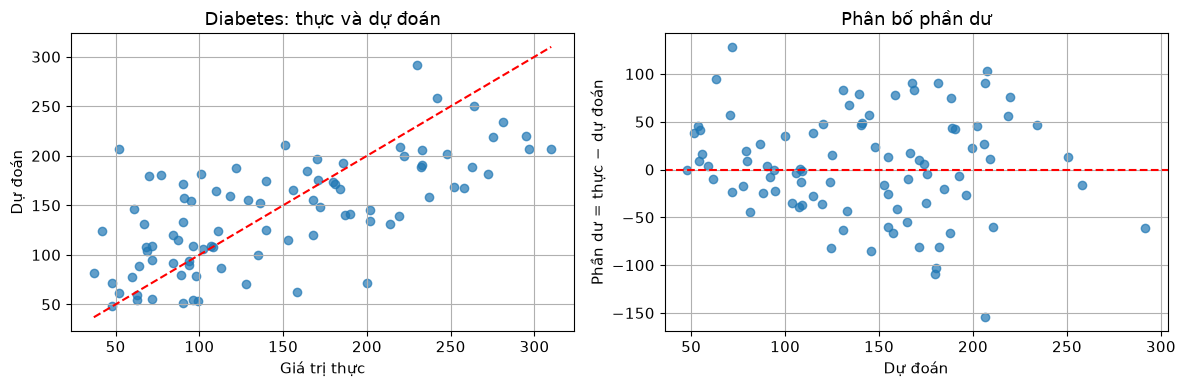

In [ ]:
# Cell 17: Kiểm tra dự đoán và phần dư để nhận biết sai số còn lại.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(yd_te, pred_d, alpha=0.7)
limits = [min(yd_te.min(), pred_d.min()), max(yd_te.max(), pred_d.max())]
axes[0].plot(limits, limits, 'r--')
axes[0].set(xlabel='Giá trị thực', ylabel='Dự đoán', title='Diabetes: thực và dự đoán')
axes[1].scatter(pred_d, yd_te - pred_d, alpha=0.7)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(xlabel='Dự đoán', ylabel='Phần dư = thực − dự đoán', title='Phân bố phần dư')
plt.tight_layout(); plt.show()

**Nhận xét:** So sánh với baseline để xác nhận mô hình có học được tín hiệu.
R² không bằng 1 cho thấy dữ liệu còn biến thiên mà mô hình tuyến tính chưa giải thích được.
Chỉ một lần chia train/test chưa đủ để kết luận khả năng tổng quát trong mọi quần thể.

## III. Bài tập về nhà
### Bài 1. Thay đổi điều kiện sinh dữ liệu
Thực hiện cả hồi quy giá nhà và phân loại BMI để minh họa ảnh hưởng của nhiễu.
Với giá nhà, giữ số mẫu 500 và dùng lại thí nghiệm nhiều seed ở bài lớp 1.

,n,sigma,MSE,RMSE,R2,RMSE_tin_hieu
3,500,100,9759.185,98.788,0.997,4.121
4,500,500,243979.618,493.941,0.923,20.606
5,500,1000,975918.472,987.882,0.753,41.211


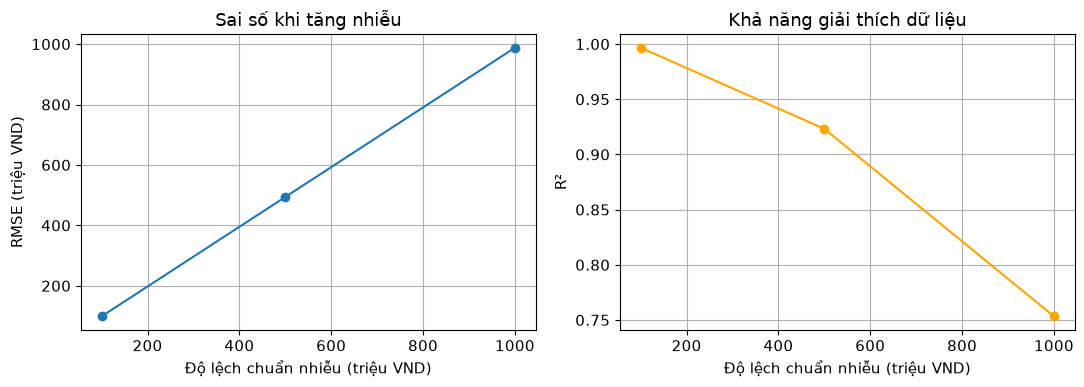

In [ ]:
# Cell 18: Tổng hợp tác động tăng nhiễu giá bán với số mẫu được giữ cố định.
noise_house = sample_experiment.query('n == 500').copy()
display(noise_house.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(noise_house['sigma'], noise_house['RMSE'], 'o-')
axes[0].set(xlabel='Độ lệch chuẩn nhiễu (triệu VND)', ylabel='RMSE (triệu VND)', title='Sai số khi tăng nhiễu')
axes[1].plot(noise_house['sigma'], noise_house['R2'], 'o-', color='orange')
axes[1].set(xlabel='Độ lệch chuẩn nhiễu (triệu VND)', ylabel='R²', title='Khả năng giải thích dữ liệu')
plt.tight_layout(); plt.show()

,mean,std
Sigma_logit,,
0,0.8588,0.0216
1,0.8318,0.0272
2,0.7810,0.0255
4,0.6975,0.0314


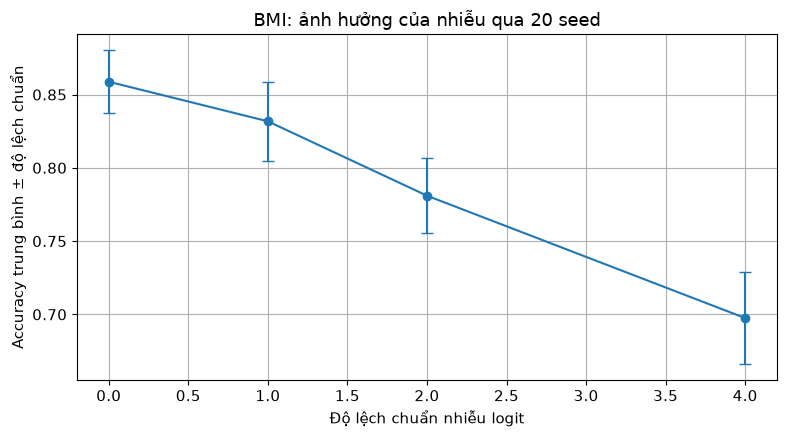

In [ ]:
# Cell 19: Thêm nhiễu vào logit BMI; giữ nguyên BMI, số ngẫu nhiên và cách chia mỗi seed.
# Nhiễu logit biểu diễn yếu tố chưa quan sát, không phải sai số trực tiếp của phép đo BMI.
bmi_noise_rows = []
for seed in range(20):
    gen = np.random.default_rng(seed)
    bx = gen.uniform(16, 40, (1000, 1))
    latent_noise = gen.normal(size=1000)
    uniform_draw = gen.uniform(size=1000)
    idx_tr, idx_te = train_test_split(np.arange(1000), test_size=0.2, random_state=seed)
    for sigma in [0, 1, 2, 4]:
        probabilities = sigmoid(0.4 * (bx[:, 0] - 27) + sigma * latent_noise)
        labels = (uniform_draw < probabilities).astype(int)
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        model.fit(bx[idx_tr], labels[idx_tr])
        predicted = model.predict(bx[idx_te])
        bmi_noise_rows.append({'Sigma_logit': sigma, 'Accuracy': accuracy_score(labels[idx_te], predicted)})
bmi_noise_summary = pd.DataFrame(bmi_noise_rows).groupby('Sigma_logit')['Accuracy'].agg(['mean', 'std'])
display(bmi_noise_summary.round(4))
plt.errorbar(bmi_noise_summary.index, bmi_noise_summary['mean'], yerr=bmi_noise_summary['std'], marker='o', capsize=4)
plt.xlabel('Độ lệch chuẩn nhiễu logit'); plt.ylabel('Accuracy trung bình ± độ lệch chuẩn')
plt.title('BMI: ảnh hưởng của nhiễu qua 20 seed'); plt.tight_layout(); plt.show()

**Nhận xét:** Khi nhiễu giá tăng, MSE/RMSE thường tăng và R² giảm.
Khi nhiễu logit tăng, BMI cung cấp ít thông tin hơn về nhãn nên accuracy trung bình thường giảm.
Độ lệch chuẩn qua nhiều seed thể hiện kết quả có dao động; đây không phải khoảng tin cậy.

### Bài 2. Thay ngưỡng dự đoán xác suất
Dùng lại **đúng mô hình và xác suất test** ở bài BMI. Chỉ đổi ngưỡng 0.5, 0.6, 0.7, 0.8,
không huấn luyện lại. Đây là khảo sát trên test; nếu cần chọn ngưỡng triển khai thì phải dùng validation riêng.

In [ ]:
# Cell 20: Tính accuracy, precision, recall, F1 và các phần tử ma trận ở mỗi ngưỡng.
threshold_rows = []
for threshold in [0.5, 0.6, 0.7, 0.8]:
    labels = (prob_bmi >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb_te, labels, labels=[0, 1]).ravel()
    threshold_rows.append({'Nguong': threshold, 'Accuracy': accuracy_score(yb_te, labels),
        'Precision': precision_score(yb_te, labels, zero_division=0),
        'Recall': recall_score(yb_te, labels, zero_division=0),
        'F1': f1_score(yb_te, labels, zero_division=0),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp, 'SoDuongTinh': labels.sum()})
threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

,Nguong,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,SoDuongTinh
0,0.5,0.8333,0.8358,0.8615,0.8485,44,11,9,56,67
1,0.6,0.8667,0.9016,0.8462,0.8730,49,6,10,55,61
2,0.7,0.8583,0.9138,0.8154,0.8618,50,5,12,53,58
3,0.8,0.8167,0.9216,0.7231,0.8103,51,4,18,47,51


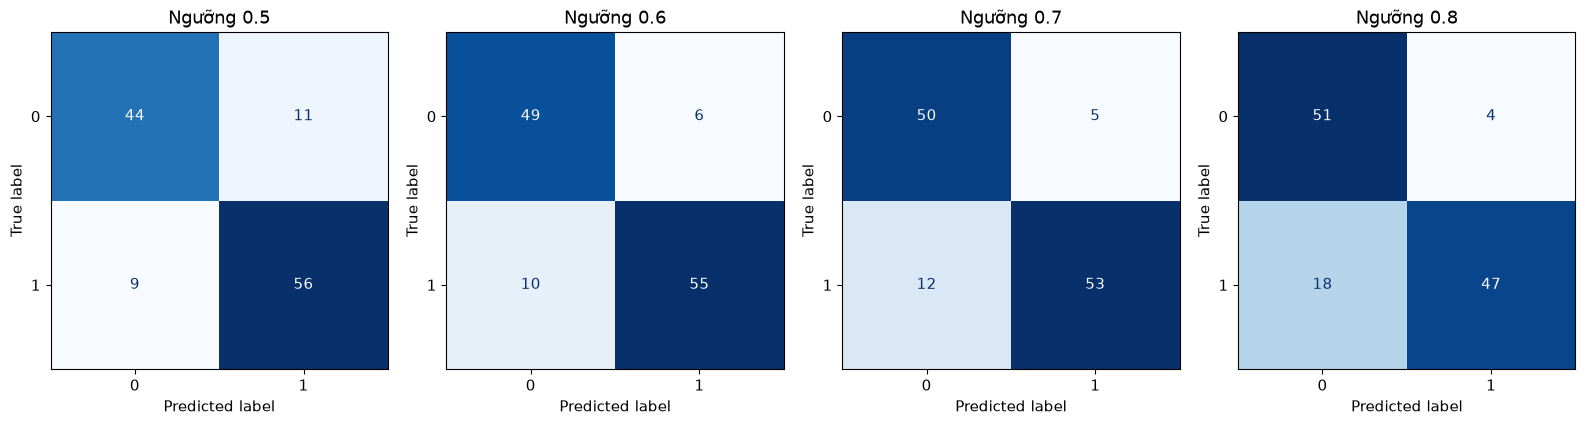

In [ ]:
# Cell 21: Vẽ ma trận nhầm lẫn để quan sát loại sai lầm thay đổi theo ngưỡng.
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, threshold in zip(axes, [0.5, 0.6, 0.7, 0.8]):
    cm = confusion_matrix(yb_te, (prob_bmi >= threshold).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['0', '1']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Ngưỡng {threshold}'); ax.grid(False)
plt.tight_layout(); plt.show()

In [ ]:
# Cell 22: Hiển thị từng dự đoán để thấy các mẫu đổi nhãn khi tăng ngưỡng.
threshold_examples = pd.DataFrame({'BMI': Xb_te['BMI'], 'NhanThuc': yb_te, 'P_benh': prob_bmi})
for threshold in [0.5, 0.6, 0.7, 0.8]:
    threshold_examples[f'Nhan_{threshold}'] = (prob_bmi >= threshold).astype(int)
display(threshold_examples.sort_values('P_benh').query('0.4 <= P_benh <= 0.85').head(20).round(3))

,BMI,NhanThuc,P_benh,Nhan_0.5,Nhan_0.6,Nhan_0.7,Nhan_0.8
311,26.005,1,0.424,0,0,0,0
496,26.354,0,0.456,0,0,0,0
399,26.616,0,0.481,0,0,0,0
591,26.757,0,0.494,0,0,0,0
26,27.201,0,0.536,1,0,0,0
34,27.269,1,0.542,1,0,0,0
37,27.417,0,0.556,1,0,0,0
321,27.542,0,0.567,1,0,0,0
221,27.726,0,0.584,1,0,0,0
559,27.839,0,0.594,1,0,0,0


**Nhận xét:** Với cùng xác suất, tăng ngưỡng khiến số dự đoán dương tính không tăng,
FP không tăng, FN không giảm và recall không tăng. Precision và accuracy không nhất thiết tăng.
Lựa chọn ngưỡng phụ thuộc mức đánh đổi giữa bỏ sót ca dương tính và báo động nhầm.

### Bài 3. Linear Regression với Boston Housing
Giữ đúng bộ dữ liệu đề yêu cầu: 506 mẫu, 13 đặc trưng, đích `MEDV` (nghìn USD).
`load_boston` đã bị bỏ từ scikit-learn 1.2; đọc CSV từ kho chính thức phiên bản 1.1.3.
[Tài liệu scikit-learn](https://scikit-learn.org/1.1/modules/generated/sklearn.datasets.load_boston.html)
giải thích việc loại bỏ, trong đó có vấn đề đạo đức ở biến mã hóa chủng tộc `B`.
Bài này tái hiện yêu cầu học phần trên dữ liệu lịch sử, không sử dụng cho định giá thực tế.

In [ ]:
# Cell 23: Ưu tiên CSV đi kèm; nếu chạy Colab thì tải từ bản phát hành cố định.
url_boston = 'https://raw.githubusercontent.com/scikit-learn/scikit-learn/1.1.3/sklearn/datasets/data/boston_house_prices.csv'
csv_boston = Path('boston_house_prices.csv')
if not csv_boston.exists() and Path('Tuan1_Regression/boston_house_prices.csv').exists():
    csv_boston = Path('Tuan1_Regression/boston_house_prices.csv')
# Dòng đầu chứa metadata 506,13; dòng tiếp theo mới là tên cột.
boston = pd.read_csv(csv_boston if csv_boston.exists() else url_boston, skiprows=1)
if 'MEDV' not in boston.columns:
    raise ValueError('CSV Boston phải có cột mục tiêu MEDV.')
assert boston.shape == (506, 14), 'Cần đúng dữ liệu Boston: 506 dòng, 13 đặc trưng + MEDV.'
inspect_data(boston)

Kích thước: (506, 14)
Số giá trị thiếu: 0
Số dòng trùng: 0


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00
mean,3.61,11.36,11.14,0.07,0.55,6.28,68.57,3.80,9.55,408.24,18.46,356.67,12.65,22.53
std,8.60,23.32,6.86,0.25,0.12,0.70,28.15,2.11,8.71,168.54,2.16,91.29,7.14,9.20
min,0.01,0.00,0.46,0.00,0.38,3.56,2.90,1.13,1.00,187.00,12.60,0.32,1.73,5.00
25%,0.08,0.00,5.19,0.00,0.45,5.89,45.02,2.10,4.00,279.00,17.40,375.38,6.95,17.02
50%,0.26,0.00,9.69,0.00,0.54,6.21,77.50,3.21,5.00,330.00,19.05,391.44,11.36,21.20
75%,3.68,12.50,18.10,0.00,0.62,6.62,94.07,5.19,24.00,666.00,20.20,396.22,16.96,25.00
max,88.98,100.00,27.74,1.00,0.87,8.78,100.00,12.13,24.00,711.00,22.00,396.90,37.97,50.00


In [ ]:
# Cell 24: Chia 80/20 và fit Linear Regression sau bước xử lý thiếu trên train.
X_bo = boston.drop(columns='MEDV'); y_bo = boston['MEDV']
Xbo_tr, Xbo_te, ybo_tr, ybo_te = train_test_split(X_bo, y_bo, test_size=0.2, random_state=SEED)
boston_model = make_pipeline(SimpleImputer(strategy='median'), LinearRegression())
boston_model.fit(Xbo_tr, ybo_tr)
pred_bo = boston_model.predict(Xbo_te)
print(f'Số mẫu train: {len(Xbo_tr)}, test: {len(Xbo_te)}')
scores_bo = regression_scores(ybo_te, pred_bo)
print(f"MSE = {scores_bo['MSE']:.4f} (nghìn USD)²")
print(f"RMSE = {scores_bo['RMSE']:.4f} nghìn USD")
print(f"R² = {scores_bo['R2']:.4f}")
display(pd.DataFrame({'ThucTe_MEDV': ybo_te, 'DuDoan_MEDV': pred_bo,
                      'SaiSo': ybo_te - pred_bo}).head(10).round(3))

Số mẫu train: 404, test: 102
MSE = 24.2911 (nghìn USD)²
RMSE = 4.9286 nghìn USD
R² = 0.6688


,ThucTe_MEDV,DuDoan_MEDV,SaiSo
173,23.6,28.997,-5.397
274,32.4,36.026,-3.626
491,13.6,14.817,-1.217
72,22.8,25.032,-2.232
452,16.1,18.770,-2.670
76,20.0,23.254,-3.254
316,17.8,17.663,0.137
140,14.0,14.341,-0.341
471,19.6,23.013,-3.413
500,16.8,20.632,-3.832


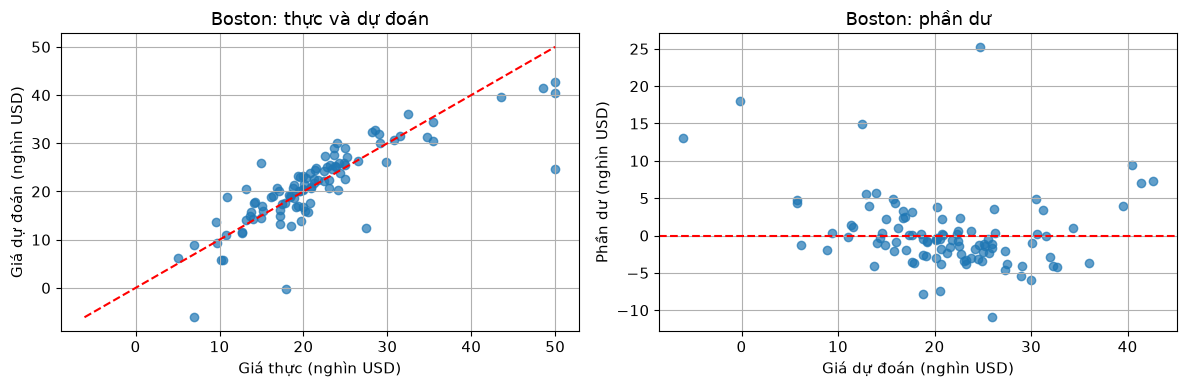

In [ ]:
# Cell 25: Trực quan hóa dự đoán Boston và phần dư trên tập test.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(ybo_te, pred_bo, alpha=0.7)
limits = [min(ybo_te.min(), pred_bo.min()), max(ybo_te.max(), pred_bo.max())]
axes[0].plot(limits, limits, 'r--')
axes[0].set(xlabel='Giá thực (nghìn USD)', ylabel='Giá dự đoán (nghìn USD)', title='Boston: thực và dự đoán')
axes[1].scatter(pred_bo, ybo_te - pred_bo, alpha=0.7)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(xlabel='Giá dự đoán (nghìn USD)', ylabel='Phần dư (nghìn USD)', title='Boston: phần dư')
plt.tight_layout(); plt.show()

**Nhận xét:** MSE có đơn vị bình phương, còn RMSE cùng đơn vị với giá nhà nên dễ diễn giải hơn.
R² cho biết mức cải thiện so với dự đoán trung bình của y test, không phải phần trăm dự đoán chính xác.
Các điểm lệch xa đường chéo cho thấy Linear Regression chưa mô tả hết quan hệ trong dữ liệu.

In [ ]:
# Cell 26: Tổng hợp kết quả chính để tiện viết báo cáo sau khi chạy toàn bộ notebook.
summary = pd.DataFrame([
    {'Bai': 'Ở lớp 1 — diện tích', **regression_scores(y_h_test, pred_h)},
    {'Bai': 'Ở lớp 1 — đa biến', **regression_scores(ym_te, multiple_m.predict(Xm_te))},
    {'Bai': 'Ở lớp 3 — Diabetes', **regression_scores(yd_te, pred_d)},
    {'Bai': 'Về nhà 3 — Boston', **scores_bo}])
display(summary.round(4))
print(f'Ở lớp 2 — BMI: accuracy = {accuracy_score(yb_te, pred_bmi):.4f}')
print('Không so sánh trực tiếp MSE giữa các bộ dữ liệu có đơn vị/thang đo khác nhau.')

,Bai,MSE,RMSE,R2
0,Ở lớp 1 — diện tích,93202.8768,305.2915,0.9695
1,Ở lớp 1 — đa biến,39945.6613,199.8641,0.9879
2,Ở lớp 3 — Diabetes,2900.1936,53.8534,0.4526
3,Về nhà 3 — Boston,24.2911,4.9286,0.6688


Ở lớp 2 — BMI: accuracy = 0.8333
Không so sánh trực tiếp MSE giữa các bộ dữ liệu có đơn vị/thang đo khác nhau.


## Kết luận
- Đã xây dựng hồi quy tuyến tính đơn biến, đa biến và mô hình logistic.
- Dữ liệu được khảo sát, tách train/test; các bước học tiền xử lý chỉ fit trên train.
- Đã khảo sát số lượng mẫu, nhiễu và ngưỡng; có bảng số liệu, biểu đồ và nhận xét.
- Boston Housing dùng đúng CSV lịch sử để tương thích scikit-learn mới.

